In [1]:
import warnings
warnings.filterwarnings("ignore")
import inspect
import numpy as np
import pandas as pd

# sklearn
from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, cross_validate, GridSearchCV, learning_curve
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer, root_mean_squared_error
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

import matplotlib.pyplot as plt


CSV = "assets/2016_Building_Energy_Benchmarking_clean.csv"
df = pd.read_csv(CSV)

TARGET = "SiteEnergyUse(kBtu)"


## Définition des métriques d’évaluation

- **RMSE** : racine de l’erreur quadratique moyenne.

- **MAE** : erreur absolue moyenne.

- **R²** : Mesure la proportion de la variance des données.


In [2]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

SCORERS = {
    "rmse": make_scorer(rmse, greater_is_better=False),
    "mae": make_scorer(mean_absolute_error, greater_is_better=False),
    "r2": "r2"
}


## Préparation des données et préprocesseur

1. Détection des types de variables

    - Les colonnes numériques sont identifiées à l’aide de pd.api.types.is_numeric_dtype.

    - Les colonnes catégorielles sont repérées si elles sont de type object ou catégoriel.

    - La variable cible  est retirée de ces listes afin d’éviter toute confusion.

2. Prévention des fuites de données

3. Définition des jeux d’entraînement et de test

    - On construit les matrices X et y .

    - On filtre uniquement les lignes où la cible est disponible.

    - On sépare les données en train/test (80% / 20%).

4. Traitements spécifiques sur les features

5. Mise en place du préprocesseur


In [3]:
# On récupère toutes les colonnes du dataset
all_cols = df.columns.tolist()

# Colonnes numériques (int, float)
num_cols = [c for c in all_cols if pd.api.types.is_numeric_dtype(df[c])]

# Colonnes catégorielles (object ou category)
cat_cols = [c for c in all_cols if df[c].dtype == "object" or pd.api.types.is_categorical_dtype(df[c])]

# On enlève la variable cible pour éviter qu’elle soit utilisée comme entrée du modèle
num_cols = [c for c in num_cols if c != TARGET]
cat_cols = [c for c in cat_cols if c != TARGET]

# Certaines colonnes (énergie, émissions, score, etc.) contiennent directement la réponse
leakage_tokens = ["EUI","kBtu","kWh","therm","GHG","Emissions","Use(kBtu)", "OSEBuildingID", "ZipCode", "CouncilDistrictCode", "ENERGYSTARScore"]

def is_leaky(col):
    s = col.lower()
    return any(tok.lower() in s for tok in leakage_tokens)

num_cols = [c for c in num_cols if not is_leaky(c)]
cat_cols = [c for c in cat_cols if not is_leaky(c)]

# X = features, y = target (cible)
X = df[num_cols + cat_cols].copy()
y = df[TARGET].copy()

# On garde seulement les lignes où y est connu
mask = y.notna()
X, y = X.loc[mask], y.loc[mask]

# Séparation en train/test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Transformation log
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)

# On borne les valeurs numériques : relève les valeurs sous le 1er percentile
q_low = 0.01
floors = {}
for c in num_cols:
    lo = X_train[c].quantile(q_low)
    floors[c] = lo
    X_train[c] = X_train[c].clip(lower=lo)
    X_test[c]  = X_test[c].clip(lower=lo)

# Dans les colonnes catégorielles, on regroupe les modalités <0.5% dans "Other" pour train
min_freq = 0.005
keepers = {}
for c in cat_cols:
    freq = X_train[c].value_counts(dropna=True, normalize=True)
    keepers[c] = set(freq[freq >= min_freq].index)
    X_train[c] = np.where(X_train[c].isin(keepers[c]), X_train[c], "Other")
    X_test[c]  = np.where(X_test[c].isin(keepers[c]),  X_test[c],  "Other")
    # On force en string pour homogénéiser
    X_train[c] = X_train[c].astype(str)
    X_test[c]  = X_test[c].astype(str)

# Pour les variables numériques : On remplace les valeurs manquantes par la médiane
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Pour les variables catégorielles : On remplace les valeurs manquantes par "Unknown"
ohe_kwargs = {"handle_unknown": "ignore"}
if "sparse_output" in inspect.signature(OneHotEncoder).parameters:
    ohe_kwargs["sparse_output"] = False
else:
    ohe_kwargs["sparse"] = False

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("ohe", OneHotEncoder(**ohe_kwargs))
])

PREP = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
], remainder="drop", verbose_feature_names_out=False)

print(f"{len(num_cols)} num, {len(cat_cols)} cat.")


8 num, 8 cat.


### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [4]:
def evaluer_modele(model, X_train, y_train, X_test, y_test, scorers=SCORERS):
  model.fit(X_train, y_train)

  y_pred_train = model.predict(X_train)
  y_pred_test = model.predict(X_test)

  scores = {}
  for name, scorer in scorers.items():
    if isinstance(scorer, str):
      func = r2_score
    else:
      func = scorer._score_func
    scores[f"{name.upper()}_train"] = func(y_train, y_pred_train)
    scores[f"{name.upper()}_test"] = func(y_test, y_pred_test)
  return scores

In [5]:
modeles = [
  ("Dummy", DummyRegressor()),
  ("LinearRegression", Pipeline([("prep", PREP), ("reg", LinearRegression())])),
  ("RandomForest", Pipeline([("prep", PREP), ("reg", RandomForestRegressor(random_state=42))])),
  ("SVR", Pipeline([("prep", PREP), ("reg", SVR())]))
]

results = []
for nom, modele in modeles:
  scores = evaluer_modele(modele, X_train, y_train, X_test, y_test)
  results.append({
    "Model": nom,
    "R2 Train": scores["R2_train"],
    "R2 Test": scores["R2_test"]
  })

pd.DataFrame(results)

,Model,R2 Train,R2 Test
0,Dummy,0.000000,-0.000165
1,LinearRegression,0.721871,0.581943
2,RandomForest,0.954465,0.626413
3,SVR,-0.151820,-0.175035


In [6]:
results_log = []
for nom, modele in modeles:
  scores = evaluer_modele(modele, X_train, y_train_log, X_test, y_test_log)
  results_log.append({
    "Model": nom,
    "R2 Train": scores["R2_train"],
    "R2 Test": scores["R2_test"]
  })

pd.DataFrame(results_log)

,Model,R2 Train,R2 Test
0,Dummy,0.000000,-0.001918
1,LinearRegression,0.660155,0.511670
2,RandomForest,0.954241,0.652453
3,SVR,0.764578,0.650234


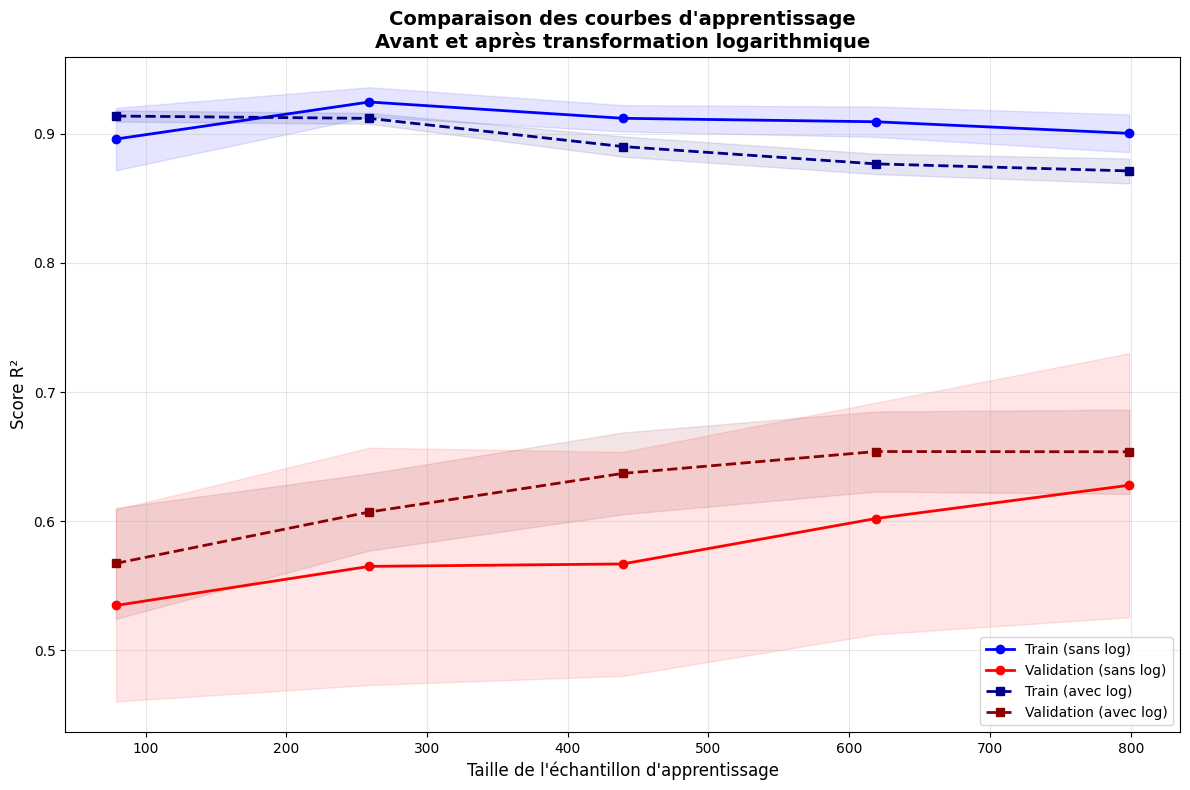


Analyse comparative:
Score R² final validation sans log: 0.6279
Score R² final validation avec log: 0.6538
Amélioration: 0.0259


In [8]:
# Création d'un graphique unique avec courbes superposées
plt.figure(figsize=(12, 8))

# Courbe d'apprentissage SANS transformation log
train_sizes, train_scores, test_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    cv=3,
    scoring="r2",
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    shuffle=True,
    random_state=42
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, "o-", label="Train (sans log)", color='blue', linewidth=2)
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
plt.plot(train_sizes, test_mean, "o-", label="Validation (sans log)", color='red', linewidth=2)
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='red')

# Courbe d'apprentissage AVEC transformation log
train_sizes_log, train_scores_log, test_scores_log = learning_curve(
    best_model,
    X_train,
    y_train_log,
    cv=3,
    scoring="r2",
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    shuffle=True,
    random_state=42
)

train_mean_log = np.mean(train_scores_log, axis=1)
train_std_log = np.std(train_scores_log, axis=1)
test_mean_log = np.mean(test_scores_log, axis=1)
test_std_log = np.std(test_scores_log, axis=1)

plt.plot(train_sizes_log, train_mean_log, "s--", label="Train (avec log)", color='darkblue', linewidth=2)
plt.fill_between(train_sizes_log, train_mean_log - train_std_log, train_mean_log + train_std_log, alpha=0.1, color='darkblue')
plt.plot(train_sizes_log, test_mean_log, "s--", label="Validation (avec log)", color='darkred', linewidth=2)
plt.fill_between(train_sizes_log, test_mean_log - test_std_log, test_mean_log + test_std_log, alpha=0.1, color='darkred')

plt.xlabel("Taille de l'échantillon d'apprentissage", fontsize=12)
plt.ylabel("Score R²", fontsize=12)
plt.title("Comparaison des courbes d'apprentissage\nAvant et après transformation logarithmique", fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calcul des améliorations
print("\nAnalyse comparative:")
print(f"Score R² final validation sans log: {test_mean[-1]:.4f}")
print(f"Score R² final validation avec log: {test_mean_log[-1]:.4f}")
print(f"Amélioration: {test_mean_log[-1] - test_mean[-1]:.4f}")

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

### Recherche d'hyperparamètres et importance des variables

une recherche par grille (`GridSearchCV`) est effectuée pour optimiser les hyperparamètres du modèle RandomForest. 
Cette étape permet d'améliorer les performances du modèle en testant différentes combinaisons de paramètres.
Une fois le meilleur modèle trouvé, on identifie les variables les plus importantes grâce à la fonctionnalité d'importance des features, ce qui permet de mieux comprendre quels attributs influencent le plus la prédiction.

Meilleurs paramètres : {'reg__max_depth': 10, 'reg__min_samples_split': 5, 'reg__n_estimators': 100}
Score R² : 0.657583839688578


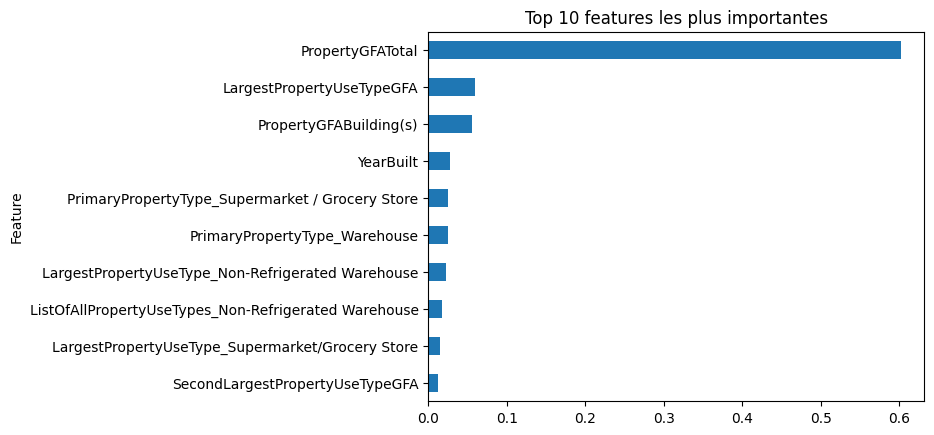

In [7]:
pipe = Pipeline([
    ("prep", PREP),
    ("reg", RandomForestRegressor(random_state=42))
])

param_grid = {
    "reg__n_estimators": [100, 200, 300, 400],
    "reg__max_depth": [5, 10, 15, None],
    "reg__min_samples_split": [2, 5]
}

grid = GridSearchCV(pipe, param_grid, cv=3, n_jobs=-1, scoring="r2")
grid.fit(X_train, y_train_log)

print("Meilleurs paramètres :", grid.best_params_)
print("Score R² :", grid.best_score_)


best_model = grid.best_estimator_
best_model.fit(X_train, y_train_log)


importances = best_model.named_steps["reg"].feature_importances_
feat_names = best_model.named_steps["prep"].get_feature_names_out()

imp_df = pd.DataFrame({
    "Feature": feat_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

imp_df.head(10).plot(kind="barh", x="Feature", y="Importance", legend=False)
plt.gca().invert_yaxis()
plt.title("Top 10 features les plus importantes")
plt.show()